In [1]:
import numpy as np
from base import utilities 
from rw import endf_reader
from process import wrappers
import matplotlib.pyplot as plt

# Compare the electron (neutrino) spectrum from different database

We will compare electron (neutrino) spectra from different database. 

In particular: JEFF4.0 (data/JEFF40-decay_data.txt), ENDF/B sub-library (data/endfb-bm.txt) and ENSDF (data/SelectedENSDFDataset.txt).

--------------------------
For ENSDF, you can download a specific ensdf file from the online database (see the first BetaShape tutorial) or you can use the one already present in the data folder.


You need to unpack into separate files using the script unpackENSDF.py (unpackENSDF.py -f example.txt -o out_path), where out_path is a directory where all the *.ensdf file will be created.

In [9]:
beta_path = ""
out_path = "."

#Initialize the object
CmdBetashape = wrappers.CmdBetaShape()
CmdBetashape.set_betashape(beta_path)
CmdBetashape.set_save_path(out_path)
example_dic =CmdBetashape.get_example_dictionary()

In [47]:
Jname = "Y96"    # nuclide for the Jeff database. name+atomic_number. If metastable, add M. e.g. Ho166M
Bname = "96Y"    # nuclide for the ENDF/b sub-library. atomi_number+name. If metastable, add _m1. e.g 166Ho_1m
Sname = "96Y.ensdf" # nuclide for the ENSDF database. atomic_number+name, all caps. If metastable, leave as is.

dtype = "data_beta" #data_beta for electron spectra, data_nu for neutrino spectra

Spath = "../data/out_path/" # path for the ensdf file
Jpath = "../data/JEFF40-decay_data.txt"  # path for the jeff database
Bpath = "../data/endfb-bm.txt"   #path for the endf/b sub-library
#=====================================

#Jeff 4.0
Jreader = endf_reader.EndfBReader()
Jreader.open_file(Jpath)
Jreader.get_element(Jname,verbose=False)
Jdic = Jreader.get_decay()
z,a,_ = endf_reader.element(Jdic["zaid"])
m = Jdic["LISO"]
print("Metastable :", m)
print("JEFF")
try:
    ensdf_dic = utilities.create_dict(z=z,a=a,m=m,data=Jdic["decay_data"],example_dic=example_dic)
    result_dic = CmdBetashape.evaluate_decay(dictionary=ensdf_dic, boptions="myEstep=1 nu=1",rmdir=True)
    Jsimple_dic = CmdBetashape.convert_output_into_dic(result_dic[int(m)], tipo = dtype)
except Exception as e: 
    print("evaluation failed:", e)
    Jsimple_dic = None
    
#endf-b sub-library
Breader = endf_reader.EndfBSubLibraryReader(Bpath) 
_,tag, data = Breader.get_element(z=z,a=a,m=m)
print("ENDF/B sub-library")
print(tag)

try:
    if tag == "discreet":
        ensdf_dic = utilities.create_dict(z=z,a=a,m=m,data=data,example_dic=example_dic)
        result_dic = CmdBetashape.evaluate_decay(dictionary=ensdf_dic, boptions="myEstep=1 nu=1",rmdir=True)
        Bsimple_dic = CmdBetashape.convert_output_into_dic(result_dic[int(m)], tipo = dtype)
    else:
        if dtype == "data_beta":
            Bsimple_dic = {"dN_dE_tot": data[:,1]}
        else:
            Bsimple_dic = {"dN_dE_tot": data[:,2]}
except Exception as e: 
    print("evaluation failed:",e)
    Bsimple_dic = None
        
#ENSDF
Sreader = endf_reader.EnsdfReader()
Sreader.open_file(Spath+Sname)
print("ENSDF")
try:
    Sdic = Sreader.get_dict()
    result_dic = CmdBetashape.evaluate_decay(ensdf_path=Spath,ensdf_name=Sname,boptions="myEstep=1 nu=1",rmdir=True)
    Ssimple_dic = CmdBetashape.convert_output_into_dic(result_dic[int(m)], tipo = dtype)
    print("Total decay probabilty:", Sdic[Bname]["BR"])
except Exception as e: 
    print("evaluation failed:",e)
    Ssimple_dic = None
    print("No ensdf file found, I will assume 100% probability of the decay")
    temp = {"BR":1}
    Sdic = {Bname:temp}

Metastable : 0
JEFF
ENDF/B sub-library
discreet
ENSDF
Total decay probabilty: 1.0


In [48]:
output = [Jsimple_dic,Bsimple_dic,Ssimple_dic]
output_label = ["jeff","endf/b_sub","ensdf"]

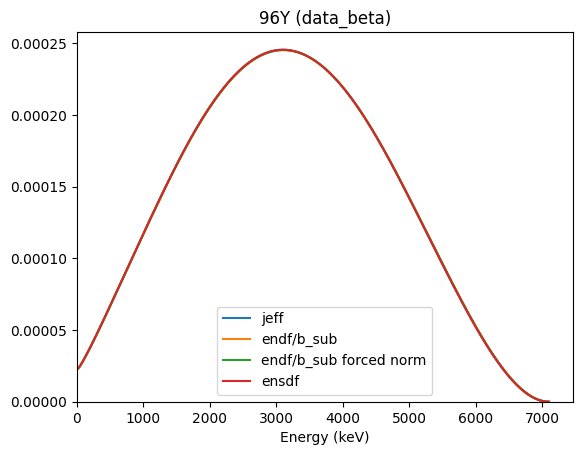

In [49]:
from scipy import integrate

x_out = []
for el in output:
    if el is not None:
        x_out.append(np.arange(len(el["dN_dE_tot"])))
    else:
        x_out.append(None)

plt.title(Bname+ " ("+ dtype+")")

for i in range(len(output)):
    if output[i] is not None:
        plt.plot(x_out[i],output[i]["dN_dE_tot"],label=output_label[i])
        if output_label[i] == "endf/b_sub":
            norm = integrate.simpson(y = output[i]["dN_dE_tot"],x = x_out[i])/Sdic[Bname]["BR"]
            
            plt.plot(x_out[i],output[i]["dN_dE_tot"]/norm,label=output_label[i]+" forced norm")


plt.xlabel("Energy (keV)")
plt.legend()
plt.ylim(0)
plt.xlim(0)
plt.show()

In [51]:
from scipy import integrate
print("True normalization:",Sdic[Bname]["BR"])

for i in range(len(output)):
    print("##### "+output_label[i]+ " #####")
    
    if ((tag == "continuum") & (output_label[i] == "endf/b_sub" )):
        print("GCM theoretical spectrum")
        print("Normalization:", integrate.simpson(y = output[i]["dN_dE_tot"],x= x_out[i]))
    else:
        print("Normalization:", np.sum(output[i]["transition_intensity"]))
        print("Ground state transition intensity:",output[i]["transition_intensity"][np.argmax(output[i]["transition_Emax"])])

    print("Mean decay energy:",integrate.simpson(y = output[i]["dN_dE_tot"]*x_out[i],x = x_out[i]), "keV")
    if output_label[i] == "endf/b_sub" :
        print("Mean decay energy after forcing normalization:",integrate.simpson(y = output[i]["dN_dE_tot"]*x_out[i]/norm,x = x_out[i]), "keV")

    print()

True normalization: 1.0
##### jeff #####
Normalization: 0.9997870000000001
Ground state transition intensity: 0.955
Mean decay energy: 3173.8148210755567 keV

##### endf/b_sub #####
Normalization: 0.9997870000000001
Ground state transition intensity: 0.955
Mean decay energy: 3177.6448450918865 keV
Mean decay energy after forcing normalization: 3178.3239770263563 keV

##### ensdf #####
Normalization: 0.9997870000000002
Ground state transition intensity: 0.955
Mean decay energy: 3174.281926341419 keV

